# Street-Level PM2.5 Estimation with XGBoost — Full Dataset
### Nested Spatial k-Fold Cross-Validation · Bayesian Hyperparameter Optimization · Spatial Bias Detection · SHAP Interpretability

This notebook implements the **XGBoost baseline model** described in Chapters 3–4 of the thesis
*"Estimating Street-Level PM2.5 Concentrations from Urban Morphology and Air Quality Sensor Networks"*
(Dela Cruz, Dizon, Dulatre, & Perez), using the **pilot testing subset** (19 sensors, 14 grid cells with enough history
after feature engineering).

**Pipeline:**
1. Data preparation & temporal feature engineering (`prep_n_proc_full.py`)
2. Spatial fold assignment via K-Means on grid-cell centroids (`spatial_cv.py`, unchanged)
3. Nested spatial k-Fold CV (outer k=4 / inner k=3) with Bayesian hyperparameter optimization
4. Spatial bias detection — Global & Local Moran's I (`spatial_bias.py`, unchanged)
5. Final production model + SHAP interpretability


## 1. Setup

In [22]:
# Bootstrap: make this notebook independent of the working directory.
# The config modules find the data folder themselves, but the cells below still hand bare filenames
# (e.g. MAPPING_CSV) to functions that use them as given, so the notebook must run with XGBoost/ as the
# working directory. Jupyter starts wherever it was launched, so set it explicitly here.
import os
import sys

_nb_dir = os.path.dirname(os.path.abspath('xgboost_pm25_pilot.ipynb')) or os.getcwd()
if os.path.basename(_nb_dir) == 'XGBoost' and os.path.isdir(os.path.join(_nb_dir, 'data')):
    os.chdir(_nb_dir)
else:  # launched from elsewhere: find XGBoost/ by its marker files
    _here = os.getcwd()
    while _here != os.path.dirname(_here):
        if os.path.isdir(os.path.join(_here, 'data')) and \
                os.path.exists(os.path.join(_here, 'prep_n_proc_pilot.py')):
            os.chdir(_here)
            break
        _here = os.path.dirname(_here)
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

import data
print(f"working directory: {os.getcwd()}")
print(f"data dir:          {data.DATA_DIR}")
print(f"outputs dir:       {data.OUT_DIR}")


working directory: C:\Users\delac\Downloads\thesis_model\XGBoost
data dir:          C:\Users\delac\Downloads\thesis_model\XGBoost\data
outputs dir:       C:\Users\delac\Downloads\thesis_model\XGBoost\outputs


In [2]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
import shap

from math import sqrt
from skopt import gp_minimize
from skopt.space import Real, Integer
from skopt.utils import use_named_args
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
np.random.seed(42)

MAPPING_CSV = 'sensor_to_grid_map_full.csv'  # written by prep_n_proc_full.py on import

print("xgboost:", xgb.__version__)


xgboost: 3.3.0


## 2. Data Preparation & Feature Engineering

Runs `prep_n_proc_full.py`, which:
- spatially joins the 18 sensors in `Master_DL_Ready.csv` to `full_morphology_grid.csv` and writes
  `sensor_to_grid_map_full.csv` (same schema as the pilot's mapping CSV)
- merges in morphology metrics + the derived `street_width_mean`
- engineers cyclical hour/day-of-week/month encodings
- computes gap-aware lags (1-4h) and rolling stats (24h, 72h) on a per-sensor hourly index
- log1p-transforms the target and drops rows whose lag/rolling window crosses a data gap


In [3]:
# prep_n_proc_pilot.py runs on import and defines: df_clean, X, y (log1p-transformed), features
from preprocessing import prep

df_clean = prep.df_clean
X, y, features = prep.X, prep.y, prep.features
groups = prep.groups

print(f"\nFeature matrix: X={X.shape}, y={y.shape} (log1p units)")
print(f"Unique Grid_IDs (spatial groups): {len(set(groups))}")
df_clean[['Location', 'Grid_ID', 'DateTime', 'Value'] + features].head()


Loading data...
Wrote C:\Users\delac\Downloads\thesis_model\XGBoost\data\sensor_to_grid_map_full.csv: 18 sensors -> 17 unique grid cells
Merging morphology metrics...
Engineering temporal features...
Computing time-aware lags & rolling stats (this replaces Master_DL_Ready.csv's own pm25_t-1/t-2/t-3, which are naive row-shifts -- see module docstring)...
Preparing model training...
Final matrix: X=(43273, 24), y=(43273,), unique groups=17

Feature matrix: X=(43273, 24), y=(43273,) (log1p units)
Unique Grid_IDs (spatial groups): 17


,Location,Grid_ID,DateTime,Value,bh_mean,bh_stdev,bldg_dens,ndvi_mean,aspect_ratio_mean,street_width_mean,...,pm25_lag_3,pm25_lag_4,pm25_diff_1_2,pm25_roll24_mean,pm25_roll24_std,pm25_roll72_mean,pm25_roll72_std,hour_x_bldg_dens,hour_x_ndvi,hour_x_aspect_ratio
0,4797640,81,2025-06-22 18:00:00+08:00,20.9,4.118918,3.926824,0.4804,0.152588,0.206025,19.992319,...,28.7,30.2,1.0,27.972083,12.830812,23.066667,11.917284,-0.480400,-0.152588,-0.206025
1,4797640,81,2025-06-22 19:00:00+08:00,17.1,4.118918,3.926824,0.4804,0.152588,0.206025,19.992319,...,21.5,28.7,-1.6,28.413750,12.370221,23.027273,11.810037,-0.464031,-0.147388,-0.199005
2,4797640,81,2025-06-22 20:00:00+08:00,17.9,4.118918,3.926824,0.4804,0.152588,0.206025,19.992319,...,22.5,21.5,-3.8,28.063750,12.573411,22.921429,11.728956,-0.416039,-0.132145,-0.178423
3,4797640,81,2025-06-22 21:00:00+08:00,40.9,4.118918,3.926824,0.4804,0.152588,0.206025,19.992319,...,20.9,22.5,0.8,27.776250,12.729205,22.833333,11.642774,-0.339694,-0.107896,-0.145682
4,4797640,81,2025-06-22 22:00:00+08:00,26.0,4.118918,3.926824,0.4804,0.152588,0.206025,19.992319,...,17.1,20.9,23.0,28.292917,13.008448,23.144828,11.781499,-0.240200,-0.076294,-0.103013


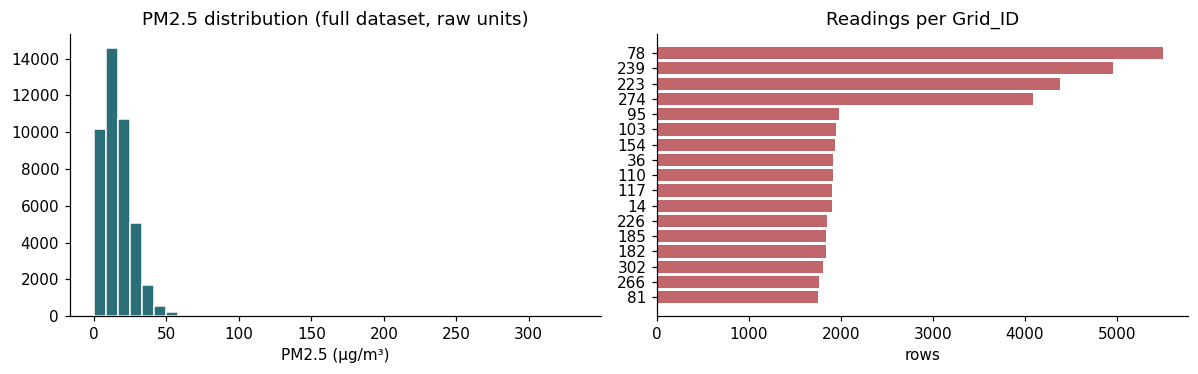

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))

axes[0].hist(df_clean['Value'], bins=40, color='#2a6f77', edgecolor='white')
axes[0].set_title('PM2.5 distribution (full dataset, raw units)')
axes[0].set_xlabel('PM2.5 (\u00b5g/m\u00b3)')

rows_per_grid = df_clean['Grid_ID'].value_counts().sort_values()
axes[1].barh(rows_per_grid.index.astype(str), rows_per_grid.values, color='#c1666b')
axes[1].set_title('Readings per Grid_ID')
axes[1].set_xlabel('rows')

plt.tight_layout()
plt.show()


## 2b. Dataset Report (Deliverable 1)

Plan Section 3.3: *"Descriptive statistics (Deliverable 1): rows kept and dropped, sensors, cells, date
range, missingness, feature distributions."*

Produced by `dataset_report.py`, which re-runs the prep module's own stages rather than re-deriving them,
so the numbers describe the artefacts that produced the model. It also **measures the drop caused by the
gap-aware lag cleaning** -- the design choice that keeps no lag feature from being a mislabelled stale
reading -- and settles the open question about grid cell 78, which holds two sensors.


In [5]:
# Deliverable 1. Writes outputs/dataset_report.md plus two CSV tables, and returns the numbers.
from reporting import dataset_report

ds = dataset_report.dataset_report(write=True)

print(f"Rows: {ds['raw_rows']:,} raw -> {ds['rows_kept']:,} kept "
      f"({100 * ds['rows_kept'] / ds['raw_rows']:.1f}%), of which "
      f"{ds['dropped_by_gap_aware_lag_cleaning']:,} lost to gap-aware lag cleaning")
print(f"Sensors: {ds['sensors_mapped_into_raster']} in raster, "
      f"{ds['sensors_outside_raster']} outside | cells with a sensor: {ds['cells_with_sensor']}")
print(f"Span: {ds['date_min']} .. {ds['date_max']} ({ds['span_days']:,} days)")

print('\nWhich requirement removes the rows:')
display(ds['drop_funnel'])
print('\nPartitions:')
display(ds['partition_table'].round(3))


wrote C:\Users\delac\Downloads\thesis_model\XGBoost\outputs\dataset_report.md
Rows: 122,841 raw -> 43,273 kept (35.2%), of which 79,568 lost to gap-aware lag cleaning
Sensors: 18 in raster, 0 outside | cells with a sensor: 17
Span: 2024-08-16 10:00:00+08:00 .. 2026-07-03 02:00:00+08:00 (685 days)

Which requirement removes the rows:


,stage,rows,lost_vs_previous
0,with a target value,122841,0
1,+ 1 h lag,100711,22130
2,+ 2 h lag,83887,16824
3,+ 3 h lag,71046,12841
4,+ 4 h lag,61106,9940
5,+ 24 h rolling mean,51205,9901
6,+ 24 h rolling sd,51205,0
7,+ 72 h rolling mean,43273,7932
8,+ 72 h rolling sd (final keep),43273,0



Partitions:


,partition,cells,rows,cell_hours,sensors,value_mean,value_sd,value_min,value_max
0,train,11,32083,31978,12,16.115,10.750,0.0,333.0
1,calibration,3,5770,5770,3,16.399,12.204,0.0,121.0
2,test,3,5420,5420,3,18.669,13.568,0.0,229.0


## 3. Spatial Fold Assignment

Per thesis Section 4.4.1, folds are assigned by **K-Means clustering the grid-cell centroids**.
`spatial_cv.py` is unchanged from the pilot notebook — it just now reads
`sensor_to_grid_map_full.csv` instead of `sensor_to_grid_map.csv`.


In [6]:
from preprocessing.spatial_cv import (get_grid_centroids, assign_spatial_folds,
                                     get_outer_folds, get_inner_folds)

outer_fold_map = get_outer_folds(MAPPING_CSV, k=4, random_state=42)
df_clean['outer_fold'] = df_clean['Grid_ID'].map(outer_fold_map)

print("Outer fold sizes (rows):")
print(df_clean['outer_fold'].value_counts().sort_index())


Outer fold sizes (rows):
outer_fold
0    14984
1     5420
2     5770
3    17099
Name: count, dtype: int64


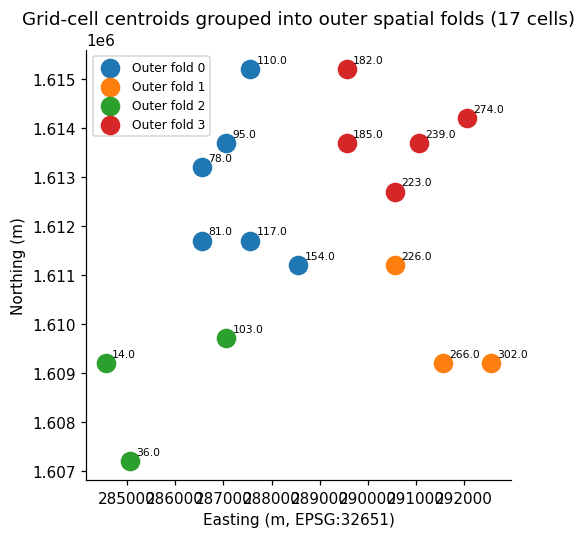

In [7]:
centroids = get_grid_centroids(MAPPING_CSV)
centroids_plot = assign_spatial_folds(centroids, k=4, random_state=42)

plt.figure(figsize=(5, 5))
for f in sorted(centroids_plot['fold'].unique()):
    sub = centroids_plot[centroids_plot['fold'] == f]
    plt.scatter(sub['cx'], sub['cy'], s=140, label=f'Outer fold {f}')
for _, r in centroids_plot.iterrows():
    plt.annotate(str(r['Grid_ID']), (r['cx'], r['cy']), fontsize=7,
                 xytext=(4, 4), textcoords='offset points')
plt.title('Grid-cell centroids grouped into outer spatial folds (17 cells)')
plt.xlabel('Easting (m, EPSG:32651)'); plt.ylabel('Northing (m)')
plt.legend(fontsize=8)
plt.tight_layout(); plt.show()


## 3b. Train / Calibration / Test Partitions + Spatial Lag (Step 2)

Per thesis Section 4.2.1, the 17 cells are split into **train (11) / calibration (3) / test (3)**
by K-Means on their centroids, chosen so the held-out partitions are geographically separated
(`min_distance_between_partitions_m` in `fold_partitions.json`). Calibration cells are what GeoCP
will use, so they must be cells this model never trained on; the test cells are the untouched read.

The split and all fold maps live in `fold_partitions.json` (built by `make_fold_partitions.py`) so
every later run reuses the same cells instead of a fresh K-Means draw.

The spatial lag is **fold-aware**: a cell is lagged from up to k=4 nearest *training* cells and
never from its own cell or a held-out cell, which is what makes the "new cell" test honest. It is
produced only for hours the neighbour pool actually covers, so gaps stay NaN, not filled.
It is NOT part of `prep.features` (that stays 24 columns) because it is fold-dependent; it is
appended to X inside each fold in the next step, where the ablation can also switch it off.


In [8]:
from preprocessing import spatial_cv
from preprocessing.spatial_cv import load_fold_map
from preprocessing import prep

# ---- the persisted split -------------------------------------------------------------
fold_doc = load_fold_map('fold_partitions.json')
partitions = fold_doc['partitions']
df_clean['partition'] = df_clean['Grid_ID'].map(
    {g: name for name, cells in partitions.items() for g in cells})

# Projected cell-centre coordinates, attached once here so every later cell (including the GeoCP
# section) can rely on them. GeoCP needs them for the kernel distances (Eq. 3.40).
centroids_by_cell = centroids.set_index('Grid_ID')
df_clean['cx'] = df_clean['Grid_ID'].map(centroids_by_cell['cx'])
df_clean['cy'] = df_clean['Grid_ID'].map(centroids_by_cell['cy'])
print(f"Attached projected centroids: cx/cy present on {df_clean[['cx', 'cy']].notna().all(axis=1).mean():.1%} of rows")

print('Partitions (cells / rows):')
for name in ['train', 'calibration', 'test']:
    cells = partitions[name]
    print(f"  {name:12s} {len(cells):2d} cells  {int((df_clean['Grid_ID'].isin(cells)).sum()):6d} rows  {cells}")
print(f"\nMin distance between partitions: "
      f"{fold_doc['info']['min_distance_between_partitions_m']} m")
print(f"Outer k={fold_doc['folds']['k_outer']}: {fold_doc['folds']['outer']}")
print(f"Inner k={fold_doc['folds']['k_inner']}: {fold_doc['folds']['inner']}")

# ---- spatial-lag coverage per partition (reported, not hidden) ------------------------
train_cells = partitions['train']
coverage = []
for name in ['train', 'calibration', 'test']:
    cells = partitions[name]
    lag = prep.compute_spatial_lag(df_clean, allowed_grid_ids=train_cells,
                                   target_grid_ids=cells, k=4)
    merged = df_clean[df_clean['Grid_ID'].isin(cells)].merge(
        lag, on=['Grid_ID', 'DateTime'], how='left')
    coverage.append({
        'partition': name, 'rows': len(merged),
        'lag_present': merged['pm25_spatial_lag'].notna().mean(),
        'median_contributors': merged['pm25_spatial_lag_n'].median(),
    })
coverage_df = pd.DataFrame(coverage)
print('\nSpatial-lag coverage (allowed = training cells only):')
print(coverage_df.round(3).to_string(index=False))
display(coverage_df.round(3))


Attached projected centroids: cx/cy present on 100.0% of rows
Partitions (cells / rows):
  train        11 cells   32083 rows  [78, 81, 95, 110, 117, 154, 182, 185, 223, 239, 274]
  calibration   3 cells    5770 rows  [14, 36, 103]
  test          3 cells    5420 rows  [226, 266, 302]

Min distance between partitions: 1500.0 m
Outer k=3: {'0': [81, 117, 154], '1': [182, 185, 223, 239, 274], '2': [78, 95, 110]}
Inner k=3: {'0': {'110': 0, '182': 0, '185': 1, '223': 1, '239': 1, '274': 1, '78': 2, '95': 2}, '1': {'110': 0, '117': 2, '154': 1, '78': 0, '81': 2, '95': 0}, '2': {'117': 2, '154': 0, '182': 1, '185': 1, '223': 1, '239': 1, '274': 1, '81': 2}}

Spatial-lag coverage (allowed = training cells only):
  partition  rows  lag_present  median_contributors
      train 32083        0.830                  3.0
calibration  5770        0.993                  4.0
       test  5420        0.996                  4.0


,partition,rows,lag_present,median_contributors
0,train,32083,0.830,3.0
1,calibration,5770,0.993,4.0
2,test,5420,0.996,4.0


## 3c. Feature arms for the ablation (Step 3)

Plan Section 3.3 (cells 7-10) asks for feature groups `TIME_ONLY`, `MORPH_TIME` and `FULL`. They are
defined in `ablation.py` and checked here so the tuning loop below can run all three **on identical
folds**, which is what makes the comparison valid.

| Arm | Features | Composition |
|---|---|---|
| **A TIME_ONLY** | 18 | 6 cyclical time + 9 PM2.5 history + 3 interactions |
| **B MORPH_TIME** | 15 | 6 morphology + 6 cyclical time + 3 interactions, **no PM2.5 history** |
| **C FULL** | 24 | morphology + cyclical time + PM2.5 history + interactions |

**Why B is the important one.** Arm C is today's notebook exactly. Arm A is the "PM2.5 predicts
itself" baseline. Arm B is the actual test of the thesis claim: can urban form predict street-level
PM2.5 *without* being handed the sensor's own recent readings? If B collapses toward A the current
framing is a persistence model; if B holds up near C, morphology is doing real work.

A fourth arm (**C+**: FULL + the fold-aware spatial lag, 27 features) is deliberately **not** run in
this pass so the A/B/C comparison stays clean. It needs the lag recomputed per outer fold and is a
separate deliverable (plan Section 3.1.5); see STATUS.md.


In [9]:
# Feature groups for the ablation. validate_arm_features() asserts the groups cover the
# import-time feature list exactly, so a typo cannot silently shrink an arm.
from training.ablation import (ARM_FEATURES, ARM_LABELS, MORPH_FEATURES, TIME_FEATURES,
                      PM_HISTORY_FEATURES, INTERACTION_FEATURES, SPATIAL_LAG_FEATURES,
                      validate_arm_features)

validate_arm_features()

print('Feature arms (all run on identical folds):')
for arm in ['A', 'B', 'C']:
    print(f"  {ARM_LABELS[arm]:16s} {len(ARM_FEATURES[arm]):2d} features")
print(f"  {'(C+ deferred)':16s} {len(ARM_FEATURES['C+']):2d} features"
      f"   <- FULL + fold-aware spatial lag, run in a later step")
print(f"\nArm C equals the import-time feature list: {ARM_FEATURES['C'] == list(features)}")
print('Spatial-lag columns absent from the import-time matrix:',
      [c for c in SPATIAL_LAG_FEATURES if c not in features])


Feature arms (all run on identical folds):
  A TIME_ONLY      18 features
  B MORPH_TIME     15 features
  C FULL           24 features
  (C+ deferred)    27 features   <- FULL + fold-aware spatial lag, run in a later step

Arm C equals the import-time feature list: True
Spatial-lag columns absent from the import-time matrix: ['pm25_spatial_lag', 'pm25_spatial_lag_w', 'pm25_spatial_lag_n']


## 4. Nested Spatial k-Fold CV with Bayesian Hyperparameter Optimization (Step 3)

Three feature arms, identical folds, calibration and test cells held out of CV, tuning and
fitting:

- **A TIME_ONLY** (18) - cyclical time + PM2.5 history + interactions
- **B MORPH_TIME** (15) - morphology + cyclical time + interactions, no PM2.5 history
- **C FULL** (24) - everything

Only the 11 training cells in `fold_partitions.json` are used. Outer k=3, inner k=3, taken from
the stored fold maps rather than re-clustered. Hyperparameters are tuned per arm with
`acq_func='EI'`. Every reported metric is in raw PM2.5 units after `expm1`; residuals are
`actual - predicted`. Full write-up of the run lands in `outputs/`.


In [10]:
# Runs the three-way ablation on the proper-training cells only. The fold maps come from
# fold_partitions.json, so these are the SAME folds the earlier cells reported and every arm is
# scored on identical held-out cells.
#
# Tuning specifics (plan Section 3.3.3): acq_func='EI' (Expected Improvement, Eq. 3.28) rather than
# skopt's default gp_hedge, per-arm tuning so no arm is handicapped by another arm's optimum, and
# metrics in raw PM2.5 units after expm1 (inner-loop selection stays in log1p units).
import json
import os

from preprocessing import prep
from training.ablation import ARM_FEATURES, ARM_LABELS, run as run_ablation

# Only the proper-training cells are fitted, tuned or scored from here on. The calibration
# and test cells stay untouched for GeoCP (step 4) and the final read.
df_train = prep.df_clean[prep.df_clean['Grid_ID'].isin(partitions['train'])].reset_index(drop=True)
print(f"Training cells: {df_train['Grid_ID'].nunique()} of 17 | rows: {len(df_train)}"
      f" | held out for calibration/test: {len(partitions['calibration']) + len(partitions['test'])} cells")

N_TRIALS = 20          # Bayesian calls per arm per outer fold. MUST match 
                       # training/ablation.py's default and the committed results: at 16 the
                       # tuning searches less and the numbers no longer match outputs/. ~9 min
                       # for all three arms.
OUT_DIR = 'outputs'
run_ablation_kwargs = dict(arms=['A', 'B', 'C'], n_trials=N_TRIALS, out_dir=OUT_DIR)

RUN_ABLATION = not (
    os.path.exists(os.path.join(OUT_DIR, 'ablation_results.csv'))
    and os.path.exists(os.path.join(OUT_DIR, 'oof_predictions_A.csv'))
    and os.path.exists(os.path.join(OUT_DIR, 'oof_predictions_B.csv'))
    and os.path.exists(os.path.join(OUT_DIR, 'oof_predictions_C.csv'))
)
print(f"Run the ablation now? {RUN_ABLATION}  "
      f"({'results not found on disk' if RUN_ABLATION else 'reusing outputs/ on disk; set '
         'RUN_ABLATION = True to force a re-run'})")

if RUN_ABLATION:
    results_df, ablation_summary, oof_by_arm = run_ablation(**run_ablation_kwargs)
else:
    results_df = pd.read_csv(os.path.join(OUT_DIR, 'ablation_results.csv'))
    ablation_summary = pd.read_csv(os.path.join(OUT_DIR, 'ablation_summary.csv'))
    oof_by_arm = {arm: pd.read_csv(os.path.join(OUT_DIR, f'oof_predictions_{arm}.csv'))
                  for arm in ['A', 'B', 'C']}

# Keep the old variable names alive so the spatial-bias cell below still works: it reads oof_df,
# which is now arm C (FULL), the arm that is comparable to the pre-Step-3 notebook.
oof_df = oof_by_arm['C'].copy()
fold_results = results_df[results_df['arm'] == 'C'].to_dict('records')

print("\n=== Ablation summary (proper-training cells only; calibration/test cells never seen) ===")
display(ablation_summary.round(3))


Training cells: 11 of 17 | rows: 32083 | held out for calibration/test: 6 cells
Run the ablation now? False  (reusing outputs/ on disk; set RUN_ABLATION = True to force a re-run)

=== Ablation summary (proper-training cells only; calibration/test cells never seen) ===


,arm,label,n_features,n_outer_folds,rmse_mean,rmse_sd,mae_mean,mae_sd,r2_mean,r2_sd,pooled_rmse,pooled_mae,pooled_r2,oof_rows
0,A,A TIME_ONLY,18,3,6.630,0.548,3.976,0.529,0.625,0.035,6.536,3.808,0.630,32083
1,B,B MORPH_TIME,15,3,10.955,1.019,7.692,0.684,-0.030,0.161,10.963,7.554,-0.040,32083
2,C,C FULL,24,3,6.697,0.503,3.977,0.538,0.617,0.035,6.631,3.808,0.619,32083


## 5. Ablation Results (Step 3)

All three arms on identical folds, calibration and test cells held out.


In [11]:
# Per-arm results. All numbers are raw PM2.5 units, from models that never saw the calibration or
# test cells. Mean/sd are across the 3 outer folds; pooled is all out-of-fold rows at once.
summary = ablation_summary.copy()
table = summary[['arm', 'n_features', 'rmse_mean', 'rmse_sd', 'mae_mean', 'mae_sd',
                 'r2_mean', 'r2_sd', 'pooled_rmse', 'pooled_mae', 'pooled_r2']].copy()
table['arm'] = table['arm'].map(ARM_LABELS)
print("=== Three-way ablation, proper-training cells only ===")
print(table.round(3).to_string(index=False))

# The headline comparison: how much of arm C's skill survives without PM2.5 history (B),
# and how much is persistence alone (A).
by_arm = summary.set_index('arm')
print("\n--- reading of the ablation ---")
print(f"  persistence alone (A):            pooled R2 = {by_arm.loc['A', 'pooled_r2']:.3f}")
print(f"  morphology + time, no history (B): pooled R2 = {by_arm.loc['B', 'pooled_r2']:.3f}")
print(f"  full model (C):                    pooled R2 = {by_arm.loc['C', 'pooled_r2']:.3f}")
print(f"\n  B vs A (morphology replacing PM2.5 history): "
      f"{by_arm.loc['B', 'pooled_r2'] - by_arm.loc['A', 'pooled_r2']:+.3f} R2")
print(f"  C vs B (adding PM2.5 history back):          "
      f"{by_arm.loc['C', 'pooled_r2'] - by_arm.loc['B', 'pooled_r2']:+.3f} R2")
print("\n  If B is near C, morphology carries real signal. If B is near A, arm C is mostly")
print("  persistence and the thesis claim needs the spatial lag / more cells to be supported.")

display(table.round(3))


=== Three-way ablation, proper-training cells only ===
         arm  n_features  rmse_mean  rmse_sd  mae_mean  mae_sd  r2_mean  r2_sd  pooled_rmse  pooled_mae  pooled_r2
 A TIME_ONLY          18      6.630    0.548     3.976   0.529    0.625  0.035        6.536       3.808      0.630
B MORPH_TIME          15     10.955    1.019     7.692   0.684   -0.030  0.161       10.963       7.554     -0.040
      C FULL          24      6.697    0.503     3.977   0.538    0.617  0.035        6.631       3.808      0.619

--- reading of the ablation ---
  persistence alone (A):            pooled R2 = 0.630
  morphology + time, no history (B): pooled R2 = -0.040
  full model (C):                    pooled R2 = 0.619

  B vs A (morphology replacing PM2.5 history): -0.671 R2
  C vs B (adding PM2.5 history back):          +0.660 R2

  If B is near C, morphology carries real signal. If B is near A, arm C is mostly
  persistence and the thesis claim needs the spatial lag / more cells to be supported.


,arm,n_features,rmse_mean,rmse_sd,mae_mean,mae_sd,r2_mean,r2_sd,pooled_rmse,pooled_mae,pooled_r2
0,A TIME_ONLY,18,6.630,0.548,3.976,0.529,0.625,0.035,6.536,3.808,0.630
1,B MORPH_TIME,15,10.955,1.019,7.692,0.684,-0.030,0.161,10.963,7.554,-0.040
2,C FULL,24,6.697,0.503,3.977,0.538,0.617,0.035,6.631,3.808,0.619


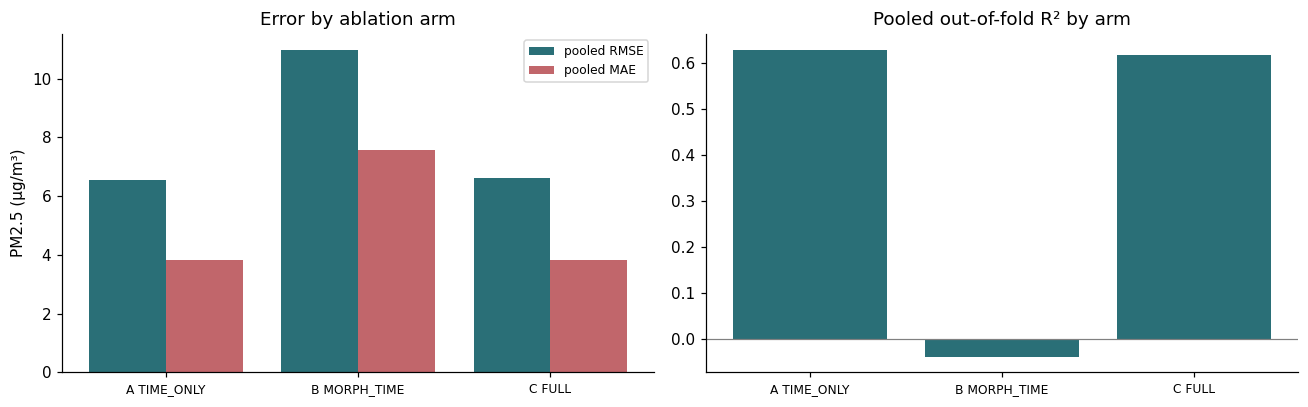

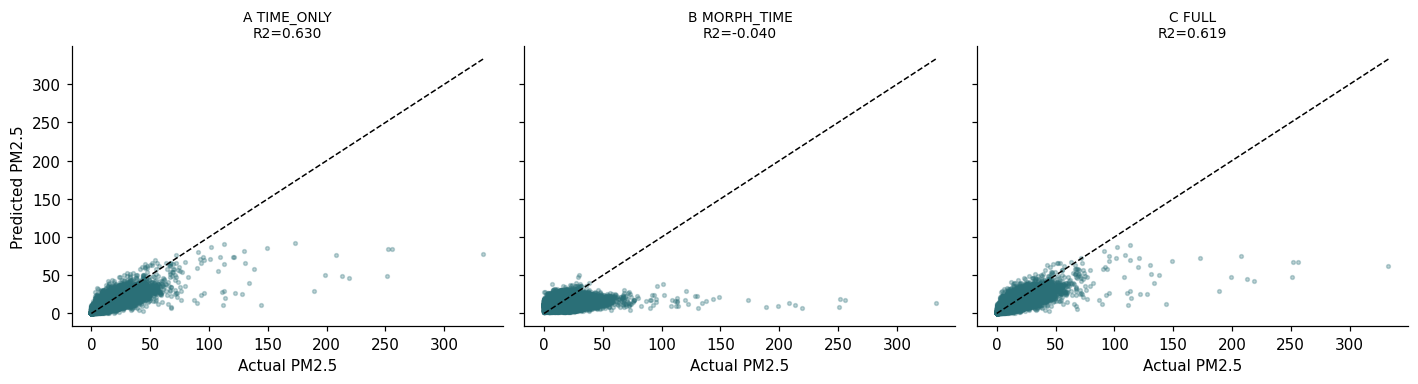

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))

labels = summary['arm'].map(ARM_LABELS).tolist()
xpos = np.arange(len(labels))
axes[0].bar(xpos - 0.2, summary['pooled_rmse'], width=0.4, color='#2a6f77', label='pooled RMSE')
axes[0].bar(xpos + 0.2, summary['pooled_mae'], width=0.4, color='#c1666b', label='pooled MAE')
axes[0].set_xticks(xpos); axes[0].set_xticklabels(labels, fontsize=8)
axes[0].set_title('Error by ablation arm'); axes[0].set_ylabel('PM2.5 (\u00b5g/m\u00b3)')
axes[0].legend(fontsize=8)

axes[1].bar(xpos, summary['pooled_r2'], color='#2a6f77')
axes[1].axhline(0, color='gray', linewidth=0.8)
axes[1].set_xticks(xpos); axes[1].set_xticklabels(labels, fontsize=8)
axes[1].set_title('Pooled out-of-fold R\u00b2 by arm')

plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharex=True, sharey=True)
lims = [oof_df['actual'].min(), oof_df['actual'].max()]
for ax, arm in zip(axes, ['A', 'B', 'C']):
    d = oof_by_arm[arm]
    ax.scatter(d['actual'], d['predicted'], s=6, alpha=0.3, color='#2a6f77')
    ax.plot(lims, lims, 'k--', linewidth=1)
    ax.set_title(f"{ARM_LABELS[arm]}\nR2={summary.set_index('arm').loc[arm, 'pooled_r2']:.3f}",
                 fontsize=9)
    ax.set_xlabel('Actual PM2.5')
axes[0].set_ylabel('Predicted PM2.5')
plt.tight_layout(); plt.show()


## 6. Spatial Bias Detection (Section 4.4.3)

`spatial_bias.py` is unchanged — it just reads `sensor_to_grid_map_full.csv`.


In [13]:
from preprocessing.spatial_bias import (aggregate_residuals_by_grid, build_knn_weights,
                                       global_morans_i, local_morans_i)

grid_residuals = aggregate_residuals_by_grid(oof_df, MAPPING_CSV)
print(f"Aggregated to {len(grid_residuals)} grid cells (mean OOF residual per cell):")
print(grid_residuals[['Grid_ID', 'residual']].sort_values('residual').to_string(index=False))

w = build_knn_weights(grid_residuals, k=4)
I, p_value = global_morans_i(grid_residuals['residual'].values, w)
print(f"\nGlobal Moran's I: {I:.3f}  (p = {p_value:.3f})")

if p_value < 0.05:
    direction = "positive (residuals of similar sign/magnitude cluster together)" if I > 0 \
        else "negative (dispersed/checkerboard pattern)"
    print(f"-> Statistically significant spatial clustering detected: {direction}")
    lisa_df = local_morans_i(grid_residuals['residual'].values, w)
    lisa_df = pd.concat([grid_residuals[['Grid_ID', 'residual']].reset_index(drop=True), lisa_df], axis=1)
    print(lisa_df.sort_values('p_sim').to_string(index=False))
else:
    print("-> No statistically significant spatial pattern in residuals "
          "(errors appear geographically random at this alpha).")


Aggregated to 11 grid cells (mean OOF residual per cell):
 Grid_ID  residual
     274  0.296363
     110  0.410376
     154  0.492958
     239  0.533096
      95  0.945807
     117  0.955314
     185  1.066903
     182  1.073376
     223  1.471270
      81  1.521815
      78  1.597241

Global Moran's I: -0.229  (p = 0.273)
-> No statistically significant spatial pattern in residuals (errors appear geographically random at this alpha).


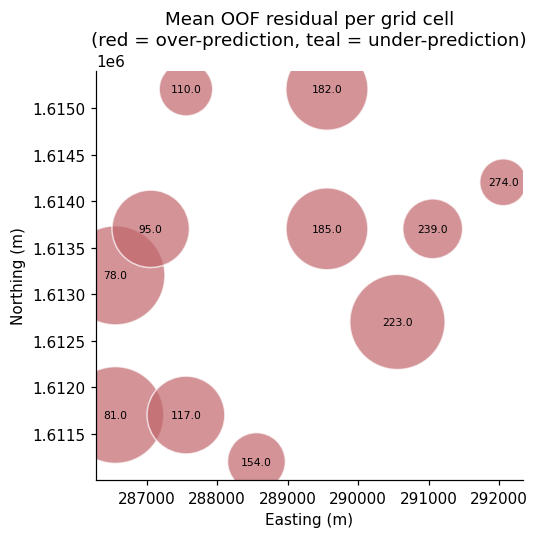

In [14]:
plt.figure(figsize=(5, 5))
sizes = 200 + 4000 * (grid_residuals['residual'].abs() / grid_residuals['residual'].abs().max())
colors = np.where(grid_residuals['residual'] >= 0, '#c1666b', '#2a6f77')
plt.scatter(grid_residuals['cx'], grid_residuals['cy'], s=sizes, c=colors, alpha=0.7, edgecolor='white')
for _, r in grid_residuals.iterrows():
    plt.annotate(str(r['Grid_ID']), (r['cx'], r['cy']), fontsize=7,
                 ha='center', va='center')
plt.title("Mean OOF residual per grid cell\n(red = over-prediction, teal = under-prediction)")
plt.xlabel('Easting (m)'); plt.ylabel('Northing (m)')
plt.tight_layout(); plt.show()


## 7. Final Production Model (Step 3)\n\nFit on the proper-training cells only, with the hyperparameters and early-stopped\n`n_estimators` of the best-generalising outer fold. The calibration and test cells have not\nbeen seen by any model in this notebook, which is the precondition for GeoCP in step 4.\n

In [15]:
# Production model. Fit on the proper-training cells ONLY: the calibration and test cells must stay
# unseen or GeoCP's conformity scores are built on data the model already memorised. Refitting on all
# 17 cells happens later, only for maps (plan Section 3.3, cell 18 note).
#
# n_estimators comes from the chosen outer fold's own early-stopped model, so no random-KFold
# selection happens anywhere in this step: every tuning decision is made on spatially held-out cells.
import json

import xgboost as xgb

# Imported explicitly rather than relying on the ablation cell above having left ARM_FEATURES
# in the notebook namespace, so this cell stands on its own.
from training.ablation import ARM_FEATURES

ARM = 'C'
arm_rows = results_df[results_df['arm'] == ARM].set_index('outer_fold')
best_fold = int(arm_rows['r2'].idxmax())
best_params = json.loads(arm_rows.loc[best_fold, 'best_params'])
production_n_estimators = int(arm_rows.loc[best_fold, 'n_estimators'])

X_prod = df_train[ARM_FEATURES[ARM]].values
y_prod = np.log1p(df_train['Value'].values)

production_model = xgb.XGBRegressor(n_estimators=production_n_estimators, random_state=42,
                                    tree_method='hist', n_jobs=-1, **best_params)
production_model.fit(X_prod, y_prod)

print(f"Arm {ARM} ({len(ARM_FEATURES[ARM])} features), hyperparameters from outer fold {best_fold} "
      f"(best generalising, R2={arm_rows.loc[best_fold, 'r2']:.3f}):")
print(f"  {best_params}")
print(f"  n_estimators = {production_n_estimators} (early stopping in that fold's own model)")
print(f"Fit on {len(df_train)} rows from {df_train['Grid_ID'].nunique()} training cells only.")
print(f"Calibration cells {partitions['calibration']} and test cells {partitions['test']} "
      f"were never used for CV, tuning or this fit.")
print("\nThis model is the input to GeoCP (step 4), which calibrates on the calibration cells and")
print("reports coverage on the test cells. It is NOT scored on held-out data here; those numbers")
print("are the ablation above.")


Arm C (24 features), hyperparameters from outer fold 0 (best generalising, R2=0.650):
  {'colsample_bytree': 0.7623873301291946, 'gamma': 0.23332831606807716, 'learning_rate': 0.03896217029789141, 'max_depth': 4, 'min_child_weight': 1, 'reg_alpha': 2.3277134043030427, 'reg_lambda': 8.861577452533078, 'subsample': 0.5115312125207079}
  n_estimators = 229 (early stopping in that fold's own model)
Fit on 32083 rows from 11 training cells only.
Calibration cells [14, 36, 103] and test cells [226, 266, 302] were never used for CV, tuning or this fit.

This model is the input to GeoCP (step 4), which calibrates on the calibration cells and
reports coverage on the test cells. It is NOT scored on held-out data here; those numbers
are the ablation above.


## 8. GeoConformal Prediction (Step 4)

Implemented from the thesis, not approximated: absolute-residual nonconformity scores (Eq. 3.36),
distances in projected metres (Eq. 3.40), kernel weights (Eq. 3.42) normalised to unity (Eq. 3.41/3.43),
the weighted quantile (Eq. 3.44/3.45), symmetric intervals (Eq. 3.46-3.50), target coverage 90%
(Section 4.5.4), and **coverage always computed on the unclipped interval** with the lower bound
clipped at zero for display only (Section 3.5.2).

The method lives in `geocp.py` and is called here, rather than re-implemented, so the notebook and
`outputs/geocp/` cannot drift apart. `verify_geocp.py` is the test suite for it (28 checks).

Two bandwidth rules are shown, because the thesis-specified one does not work at this network
density: the Section 4.5.3 grid search picks the narrowest bandwidth, which concentrates all weight on
a single calibration cell and **under-covers**. It is reported as degraded, with the geometry-only
`median-distance` alternative alongside it as the working pilot.


In [16]:
# GeoCP is a post-prediction layer: it calibrates on the calibration cells using the production
# model already fitted above, then builds intervals for the held-out test cells.
from uncertainty import geocp

ALPHA = 0.10        # nominal coverage 90% (thesis Section 4.5.4)
KERNEL = 'gaussian'  # the manuscript does not name a kernel; this is the standard geoconformal choice

cal_scores = geocp.calibration_scores_for_model(production_model, df_clean,
                                                partitions['calibration'])
print(f"Calibration nonconformity scores: {len(cal_scores)} records from "
      f"{cal_scores['Grid_ID'].nunique()} cells -> {sorted(cal_scores['Grid_ID'].unique())}")
print(cal_scores.groupby('Grid_ID')['alpha']
      .agg(['size', 'mean', 'median', lambda s: s.quantile(0.9)])
      .rename(columns={'<lambda_0>': 'p90'}).round(3).to_string())


Calibration nonconformity scores: 5770 records from 3 cells -> [np.int64(14), np.int64(36), np.int64(103)]
         size   mean  median     p90
Grid_ID                             
14       1904  6.674   3.922  14.788
36       1918  3.699   2.675   8.055
103      1948  3.036   2.049   6.871


In [17]:
# Bandwidth: the thesis-specified grid search (Section 4.5.3), plus the geometry-only alternative.
# cx/cy were attached to df_clean in the Step 2 cell
test_xy = df_clean[df_clean['Grid_ID'].isin(partitions['test'])][['cx', 'cy']].values

h_grid, curve, rule_grid, degraded = geocp.resolve_bandwidth(
    cal_scores, ALPHA, KERNEL, geocp.H_GRID, 'thesis-grid', None, True, query_xy=test_xy)
h_med, _, rule_med, _ = geocp.resolve_bandwidth(
    cal_scores, ALPHA, KERNEL, geocp.H_GRID, 'median-distance', None, True, query_xy=test_xy)

print(f"thesis grid search  -> h = {h_grid:.0f} m   degraded = {degraded}")
print(f"  {rule_grid}")
print(f"\ngeometry-only       -> h = {h_med:.0f} m")
print(f"  {rule_med}")
if degraded:
    print("\n  NOTE: no bandwidth reached 90% on every calibration fold, so the selected h is not")
    print("  coverage-valid. The unweighted split-conformal interval is the primary result and")
    print("  GeoCP is reported as a pilot, exactly as geocp.py does on the command line.")
print("\nSection 4.5.3 bandwidth curve (worst-fold coverage vs average width):")
display(curve[['h', 'worst_fold_coverage', 'mean_fold_coverage', 'mean_width']].round(3))


thesis grid search  -> h = 500 m   degraded = True
  no h reached the target coverage within 0.02 on every fold; chose the largest worst-fold coverage (report as an under-covering pilot) -- DEGRADED: no bandwidth reached the target coverage on every calibration fold, so the selected bandwidth is not coverage-valid. Report the unweighted split-conformal interval as the primary calibrated result and GeoCP as a pilot.

geometry-only       -> h = 4528 m
  h = median distance from the query cells to their nearest calibration observation (4528 m); geometry only, no labels used

  NOTE: no bandwidth reached 90% on every calibration fold, so the selected h is not
  coverage-valid. The unweighted split-conformal interval is the primary result and
  GeoCP is reported as a pilot, exactly as geocp.py does on the command line.

Section 4.5.3 bandwidth curve (worst-fold coverage vs average width):


,h,worst_fold_coverage,mean_fold_coverage,mean_width
0,500.0,0.742,0.904,25.113
1,750.0,0.738,0.902,24.779
2,1000.0,0.729,0.898,23.938
3,1500.0,0.723,0.892,22.196
4,2000.0,0.720,0.889,21.230
5,3000.0,0.720,0.884,20.196
6,4000.0,0.718,0.883,19.884
7,5000.0,0.718,0.883,19.795
8,6500.0,0.718,0.882,19.670
9,8000.0,0.718,0.881,19.609


In [18]:
# Intervals and evaluation on the final spatial test partition (unclipped intervals, per thesis).
test = df_clean[df_clean['Grid_ID'].isin(partitions['test'])].reset_index(drop=True)
assert test[['cx', 'cy']].notna().all().all(), 'missing centroid for a test cell'
ctx_geo = {'test': test, 'parts': partitions}

summary_parts = []
for label, h in [('GeoCP (thesis grid)', h_grid), ('GeoCP (median distance)', h_med)]:
    intervals = geocp.evaluate(ctx_geo, cal_scores, ALPHA, h, KERNEL, True,
                             model=production_model)
    s = geocp.summarise(intervals, ALPHA, h, KERNEL, f'{label}, h={h:.0f} m')
    summary_parts.append(s)
    glob = s[s['scope'] == 'all test observations']
    print(f"\n=== {label}, h = {h:.0f} m ===")
    print(glob[['method', 'empirical_coverage', 'mean_width', 'median_width',
                'mean_width_to_prediction']].round(3).to_string(index=False))
    print('coverage by distance to the nearest calibration sensor:')
    print(s[s['scope'] != 'all test observations'][['scope', 'method', 'n', 'empirical_coverage']]
          .round(3).to_string(index=False))
    w = intervals['geocp_top_cell_weight'].mean()
    e = intervals['geocp_effective_n_cells'].mean()
    print(f"weight concentration: top single calibration cell carries {w:.3f} of the weight, "
          f"effective cells {e:.2f} of {cal_scores['Grid_ID'].nunique()}")

geocp_summary = pd.concat(summary_parts, ignore_index=True)
geocp_summary.to_csv(os.path.join('outputs', 'geocp', 'geocp_coverage_notebook.csv'), index=False)
intervals.to_csv(os.path.join('outputs', 'geocp', 'geocp_intervals_notebook.csv'), index=False)
print("\nwrote outputs/geocp/geocp_coverage_notebook.csv and geocp_intervals_notebook.csv")



=== GeoCP (thesis grid), h = 500 m ===
                      method  empirical_coverage  mean_width  median_width  mean_width_to_prediction
                       GeoCP               0.693      11.531        10.380                     1.095
Split conformal (unweighted)               0.862      19.375        19.375                     1.873
coverage by distance to the nearest calibration sensor:
                    scope                       method    n  empirical_coverage
 nearer half (urban core)                        GeoCP 3614               0.717
 nearer half (urban core) Split conformal (unweighted) 3614               0.864
farther half (peripheral)                        GeoCP 1806               0.644
farther half (peripheral) Split conformal (unweighted) 1806               0.858
                 cell 226                        GeoCP 1852               0.751
                 cell 226 Split conformal (unweighted) 1852               0.848
                 cell 266                

## 9. Feature Importance & SHAP Interpretability (Section 4.6.4)

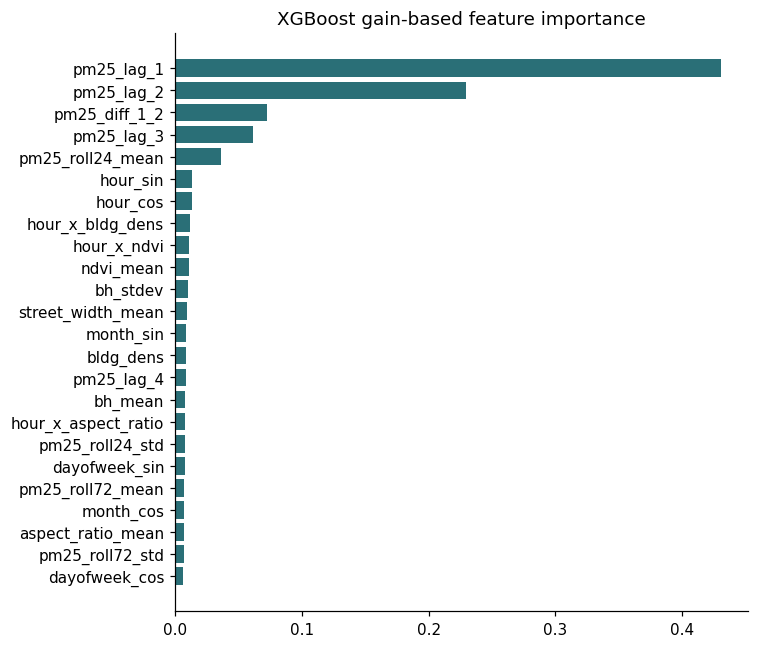

In [19]:
importances = pd.Series(production_model.feature_importances_, index=features).sort_values()

plt.figure(figsize=(7, 6))
plt.barh(importances.index, importances.values, color='#2a6f77')
plt.title('XGBoost gain-based feature importance')
plt.tight_layout(); plt.show()


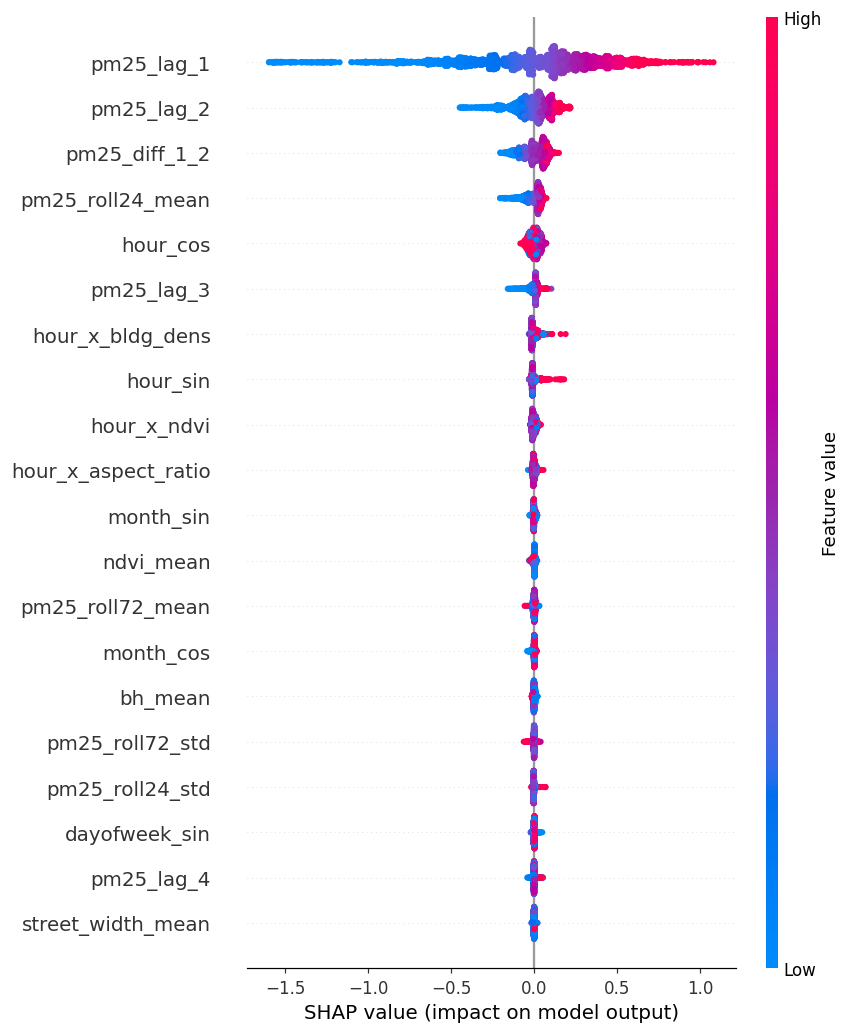

In [20]:
explainer = shap.TreeExplainer(production_model)
X_sample = X if X.shape[0] <= 3000 else X[np.random.choice(X.shape[0], 3000, replace=False)]
shap_values = explainer.shap_values(X_sample)

shap.summary_plot(shap_values, X_sample, feature_names=features, show=False)
plt.tight_layout(); plt.show()


In [21]:
morphology_features = ['bh_mean', 'bh_stdev', 'bldg_dens', 'ndvi_mean',
                       'aspect_ratio_mean', 'street_width_mean']
shap_df = pd.DataFrame(shap_values, columns=features)
mean_abs_shap = shap_df.abs().mean().sort_values(ascending=False)

print("Mean |SHAP value| per feature (log1p-target units):")
print(mean_abs_shap.round(3).to_string())

morph_share = mean_abs_shap[morphology_features].sum() / mean_abs_shap.sum()
print(f"\nShare of total |SHAP| attributable to urban-morphology features: {morph_share:.1%}")


Mean |SHAP value| per feature (log1p-target units):
pm25_lag_1             0.338
pm25_lag_2             0.083
pm25_diff_1_2          0.056
pm25_roll24_mean       0.035
hour_cos               0.023
pm25_lag_3             0.016
hour_x_bldg_dens       0.015
hour_sin               0.014
hour_x_ndvi            0.009
hour_x_aspect_ratio    0.005
month_sin              0.005
ndvi_mean              0.004
pm25_roll72_mean       0.004
month_cos              0.004
bh_mean                0.004
pm25_roll72_std        0.003
pm25_roll24_std        0.003
dayofweek_sin          0.003
pm25_lag_4             0.003
street_width_mean      0.002
dayofweek_cos          0.002
aspect_ratio_mean      0.002
bldg_dens              0.002
bh_stdev               0.001

Share of total |SHAP| attributable to urban-morphology features: 2.5%


## 10. Summary

- **18 sensors / 17 grid cells / ~43k rows** after gap-aware lag cleaning (vs. the pilot's 19
  sensors / 14 cells / ~14.6k rows) — a real increase in both spatial and temporal coverage,
  though smaller than the "46-sensor" figure floated earlier once the actual `Master_DL_Ready.csv`
  was checked (it holds 18 sensors that survived the CNN-LSTM branch's own spatial + data-quality
  filtering, not 46).
- **Nested spatial CV** (outer k=4, inner k=3) gives an unbiased read on generalization to unseen
  grid cells, same as the pilot, now on the larger dataset.
- **A genuine data bug was found and fixed**: `Master_DL_Ready.csv`'s built-in `pm25_t-1/t-2/t-3`
  columns mislabel readings during timestamp gaps (confirmed directly on the raw data). Recomputing
  them time-aware, rather than reusing them, avoids quietly feeding the model wrong lag values.
- **`street_width_mean` was added** to actually complete the paper's declared 8-feature list
  (previously missing from the feature matrix entirely).
- **Spatial-lag (neighbor-cell) features were deliberately left out**, since they'd conflict with
  the paper's stated design of scoping predictors to each sensor's own buffer.
- Compare `results_df['r2'].mean()` here against the CNN-LSTM's spatial-CV R² directly — both now
  run on the same 18-sensor data, so the comparison means what it looks like it means.
